# Imports

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Konstante
G = 6.67430e-11        # gravitacijska konstanta [m^3 kg^-1 s^-2]
M_Z = 5.972e24         # masa Zemlje [kg]
R_Z = 6371e3           # polmer Zemlje [m]
rho_0 = 1.225          # gostota zraka na površini [kg/m^3]
M_zraka = 28.96        # molska masa zraka [kg/kmol]
R_plin = 8314.46       # splošna plinska konstanta [J/(kmol K)]
T_0 = 288.15           # temperatura ozračja [K]

# Raketa
C_d = 0.2              # koeficient upora
S = 10.0               # prečni presek [m^2]
F_pot = 845e3          # sila potiska (Merlin 1D, morska gladina) [N]
v_izp = 2500.0         # izstopna hitrost plinov [m/s]
mdot = F_pot / v_izp   # poraba goriva [kg/s]
m_rak = 10_000         # suha masa rakete [kg]
m_tov = 1_000          # masa tovora [kg]
m_gor0 = 20_000        # začetna masa goriva [kg]

g0 = G * M_Z / R_Z**2  # težni pospešek na površini
H = R_plin * T_0 / (M_zraka * g0)  # višinska skala ozračja (P1)

# Funkcije

In [11]:
def gravitacijska_sila(h, m):
    """Gravitacijska sila na maso m na višini h nad površjem (negativna = navzdol)."""
    return -G * M_Z * m / (R_Z + h)**2


def gostota(h):
    """Gostota zraka po barometrski enačbi (izotermno ozračje)."""
    return rho_0 * np.exp(-np.maximum(h, 0) / H)


def sila_upora(h, v):
    """Sila zračnega upora, vedno nasprotna hitrosti."""
    return -0.5 * gostota(h) * C_d * S * v * abs(v)


def sila_potiska(m_g):
    """Konstantna sila potiska, dokler je na voljo gorivo."""
    return F_pot if m_g > 0 else 0.0


def korak(st, dt, gravitacija=True, upor=True):
    """En korak eksplicitne Eulerjeve metode. st je slovar s ključi t, h, v, m_g.
    Vrne nov slovar stanja in pospešek a v začetku koraka."""
    m = m_rak + m_tov + st["m_g"]
    F = sila_potiska(st["m_g"])
    if gravitacija:
        F += gravitacijska_sila(st["h"], m)
    if upor:
        F += sila_upora(st["h"], st["v"])
    a = F / m
    nov = {"t": st["t"] + dt,
           "h": st["h"] + st["v"] * dt,
           "v": st["v"] + a * dt,
           "m_g": max(st["m_g"] - mdot * dt, 0.0)}
    return nov, a


def simulacija(m_g0=m_gor0, dt=0.01, gravitacija=True, upor=True, konec="vrh"):
    """Simulira navpični let. konec="vrh": do najvišje točke (v < 0),
    konec="izgorevanje": do porabe goriva. Vrne DataFrame."""
    st = {"t": 0.0, "h": 0.0, "v": 0.0, "m_g": float(m_g0)}
    zapis = []
    while True:
        nov, a = korak(st, dt, gravitacija, upor)
        m = m_rak + m_tov + st["m_g"]
        zapis.append({**st, "a": a, "m": m,
                      "F_g": gravitacijska_sila(st["h"], m),
                      "F_u": sila_upora(st["h"], st["v"]),
                      "F_p": sila_potiska(st["m_g"])})
        if konec == "vrh" and nov["v"] < 0 and st["t"] > 0:
            break
        if konec == "izgorevanje" and st["m_g"] <= 0:
            break
        st = nov
    return pd.DataFrame(zapis)


def ciolkovski(m0, mk):
    """Sprememba hitrosti po raketni enačbi (brez gravitacije in upora)."""
    return v_izp * np.log(m0 / mk)


def visina_vrha(h_b, v_b):
    """Najvišja točka po izgorevanju iz ohranitve energije (brez upora, g(h))."""
    return G * M_Z / (G * M_Z / (R_Z + h_b) - v_b**2 / 2) - R_Z

# Testno območje

In [12]:
print(f"g0 = {g0:.3f} m/s^2, H = {H:.0f} m, mdot = {mdot:.0f} kg/s")
print("rho(0)   =", gostota(0.0))
print("rho(H)/rho0 =", gostota(H) / rho_0, "(pričakovano 1/e =", np.exp(-1), ")")
print("F_g(0, 1 kg) =", gravitacijska_sila(0.0, 1.0))
print("F_u(0, +100 m/s) =", sila_upora(0.0, 100.0), "| F_u(0, -100 m/s) =", sila_upora(0.0, -100.0))
print("čas izgorevanja t_b =", m_gor0 / mdot, "s")

g0 = 9.820 m/s^2, H = 8424 m, mdot = 338 kg/s
rho(0)   = 1.225
rho(H)/rho0 = 0.36787944117144233 (pričakovano 1/e = 0.36787944117144233 )
F_g(0, 1 kg) = -9.819973426224687
F_u(0, +100 m/s) = -12250.000000000002 | F_u(0, -100 m/s) = 12250.000000000002
čas izgorevanja t_b = 59.171597633136095 s


# Naloga 1 - Slika 1

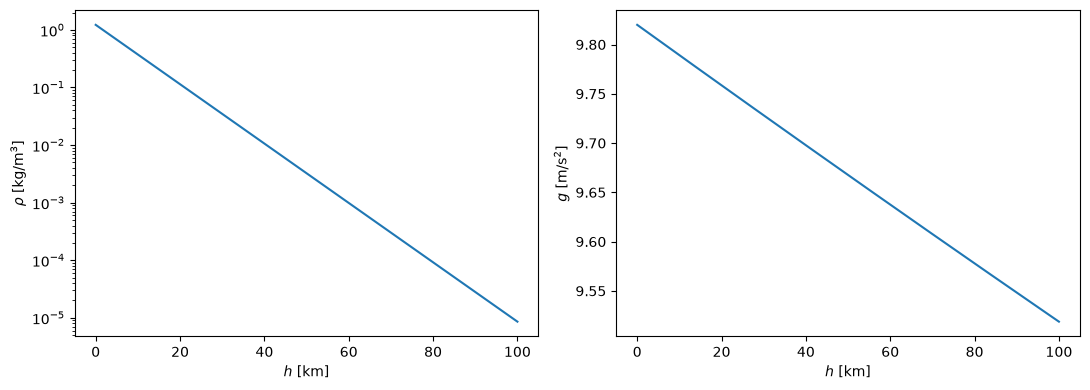

0.37378514291434817 9.51881142214778


In [13]:
h = np.linspace(0, 100e3, 500)
fig = plt.figure(figsize=(11, 4))
ax = fig.add_subplot(121)
ax.plot(h / 1e3, gostota(h))
ax.set_xlabel("$h$ [km]")
ax.set_ylabel(r"$\rho$ [kg/m$^3$]")
ax.set_yscale("log")
ax = fig.add_subplot(122)
ax.plot(h / 1e3, -gravitacijska_sila(h, 1.0))
ax.set_xlabel("$h$ [km]")
ax.set_ylabel("$g$ [m/s$^2$]")
fig.tight_layout()
plt.show()

rho_10km = gostota(10e3)
g_100km = -gravitacijska_sila(100e3, 1.0)
print(rho_10km, g_100km)

# Naloga 2

In [14]:
df = simulacija(m_gor0, dt=0.01)
df.head()

,t,h,v,m_g,a,m,F_g,F_u,F_p
0,0.00,0.000000,0.000000,20000.00,17.438091,31000.00,-304419.176213,-0.000000,845000.0
1,0.01,0.000000,0.174381,19996.62,17.441062,30996.62,-304385.984703,-0.037251,845000.0
2,0.02,0.001744,0.348792,19993.24,17.444032,30993.24,-304352.793026,-0.149028,845000.0
3,0.03,0.005232,0.523232,19989.86,17.446999,30989.86,-304319.601183,-0.335370,845000.0
4,0.04,0.010464,0.697702,19986.48,17.449965,30986.48,-304286.409173,-0.596314,845000.0


# Naloga 2 - Slika 2

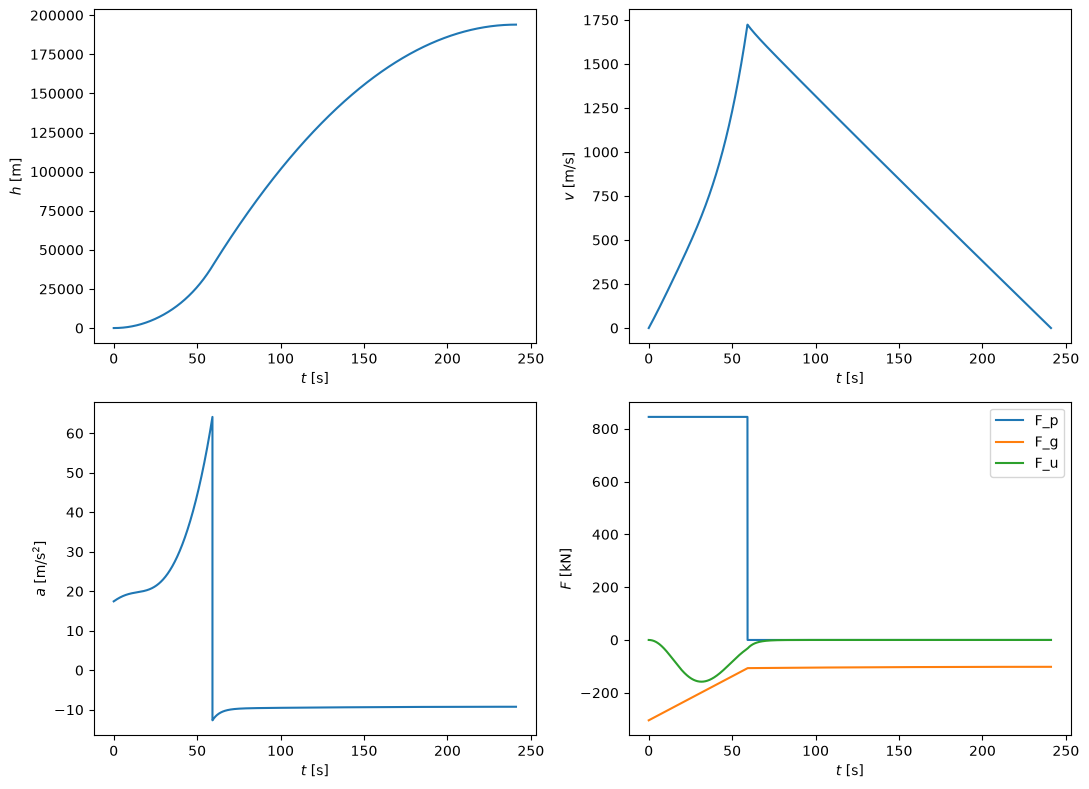

In [15]:
fig = plt.figure(figsize=(11, 8))
for k, (stolpec, oznaka) in enumerate([("h", "$h$ [m]"), ("v", "$v$ [m/s]"), ("a", "$a$ [m/s$^2$]")]):
    ax = fig.add_subplot(2, 2, k + 1)
    ax.plot(df["t"], df[stolpec])
    ax.set_xlabel("$t$ [s]")
    ax.set_ylabel(oznaka)
ax = fig.add_subplot(224)
for stolpec in ("F_p", "F_g", "F_u"):
    ax.plot(df["t"], df[stolpec] / 1e3, label=stolpec)
ax.set_xlabel("$t$ [s]")
ax.set_ylabel("$F$ [kN]")
ax.legend()
fig.tight_layout()
plt.show()

In [16]:
# Preglednica 2
izg = df[df["m_g"] > 0].iloc[-1]  # zadnji korak s potiskom
print(f"t_b = {izg['t']:.1f} s, h_b = {izg['h']/1e3:.1f} km, v_b = {izg['v']:.0f} m/s")
print(f"a_max = {df['a'].max():.1f} m/s^2 ({df['a'].max()/g0:.1f} g)")
print(f"h_max = {df['h'].max()/1e3:.1f} km pri t = {df['t'].iloc[-1]:.1f} s")
# df.to_excel("rezultati_simulacije.xlsx")  # izvoz rezultatov

t_b = 59.2 s, h_b = 39.6 km, v_b = 1723 m/s
a_max = 64.1 m/s^2 (6.5 g)
h_max = 194.0 km pri t = 241.1 s


# Naloga 3

In [17]:
m0, mk = m_rak + m_tov + m_gor0, m_rak + m_tov
dv_teor = ciolkovski(m0, mk)
for g_on, u_on in [(False, False), (True, False), (True, True)]:
    d = simulacija(m_gor0, dt=0.01, gravitacija=g_on, upor=u_on, konec="izgorevanje")
    print(f"gravitacija={g_on!s:5} upor={u_on!s:5}  v_b = {d['v'].iloc[-1]:7.1f} m/s")
print(f"Ciolkovski: {dv_teor:.1f} m/s, ocena gravitacijske izgube g0*t_b = {g0 * m_gor0 / mdot:.0f} m/s")

gravitacija=False upor=False  v_b =  2590.6 m/s
gravitacija=True  upor=False  v_b =  2012.0 m/s
gravitacija=True  upor=True   v_b =  1723.3 m/s
Ciolkovski: 2590.2 m/s, ocena gravitacijske izgube g0*t_b = 581 m/s


# Naloga 4

In [18]:
for u_on in (False, True):
    d = simulacija(m_gor0, dt=0.01, upor=u_on)
    izg = d[d["m_g"] > 0].iloc[-1]
    print(f"upor={u_on!s:5}  h_b = {izg['h']/1e3:6.1f} km, v_b = {izg['v']:6.0f} m/s, "
          f"h_max(energija) = {visina_vrha(izg['h'], izg['v'])/1e3:7.1f} km, "
          f"h_max(simulacija) = {d['h'].max()/1e3:7.1f} km")

upor=False  h_b =   46.5 km, v_b =   2011 m/s, h_max(energija) =   262.5 km, h_max(simulacija) =   262.7 km
upor=True   h_b =   39.6 km, v_b =   1723 m/s, h_max(energija) =   196.4 km, h_max(simulacija) =   194.0 km
